## <b> Hotel Booking Demand: Why Do Guests Cancel? </b>

### Project Overview

Cancellations are a big problem for hotels. An empty room that was booked and then canceled is lost money. In this project I analyze **119,390 bookings** from two hotels in Portugal: a City Hotel and a Resort Hotel (arrival dates from July 2015 to August 2017). The data comes from the Kaggle dataset *Hotel Booking Demand*.

I worked in a hotel myself, so I use my knowledge of hotel operations to ask practical questions and to check if the numbers make sense.

**Main question:** Which bookings are most likely to be canceled, and what can a hotel do about it?

**What I do in this notebook:**
1. **Clean the data:** fix missing values, remove duplicates and impossible rows.
2. **Analyze cancellations:** look at hotel type, lead time, market segment, deposit type, repeated guests and special requests.
3. **Look at seasonality and prices:** guests and average daily rate (ADR) by month, family guests, length of stay.
4. **Check operations and repeated guests:** room changes and loyalty.
5. **Check trends and test two ideas with statistics.**
6. **Give business recommendations.**

**A note about money:** the dataset does not say which currency is used. I assume euros (€) because the hotels are in Portugal. "Revenue" in this notebook is an *estimate*: ADR × number of nights.

### Key Findings

- **27.7%** of all bookings were canceled. The City Hotel has a higher rate (30.2%) than the Resort Hotel (23.7%).
- The longer the guest books in advance, the more likely they cancel: **8.5%** for bookings made 0–7 days before arrival, **39.9%** for bookings made more than 180 days before.
- **Online travel agencies (Online TA)** bring 59% of all bookings and have the highest cancellation rate (**35.6%**). Direct, Offline TA/TO and Corporate bookings are much more stable (12–15%).
- Repeated guests cancel much less (**8.2%** vs 28.4%). Guests who make at least one special request also cancel less (**21.8%** vs 33.5%), mostly in the City Hotel.
- The Resort Hotel changes its prices a lot during the year (ADR: about **€46 in January, €190 in August**). The City Hotel is calmer (about €76 to €125).
- Cancellations grew from 2015 to 2017. This is true also when I compare the same months (July–August) in each year.
- Guests with children bring more revenue per booking (**+43% in the City Hotel, +80% in the Resort Hotel**).

### Key Recommendations
- **Shift guests to Direct bookings with perks, not discounts:** offer late check-out or a welcome drink on the hotel website to save agency commissions without lowering ADR.
- **Tighten rules for high-risk bookings:** introduce partial prepayments or non-refundable rates for Online TA and Group bookings made 90+ days in advance.
- **Collect guest preferences after booking:** send a short pre-arrival form (especially in the City Hotel), as guests with special requests cancel significantly less.
- **Target families and shoulder seasons:** promote family packages in the Resort Hotel and run special offers in winter months (Jan–Feb, Nov–Dec) to boost occupancy.

### <b>  0. Setup </b>

I import the libraries and set one simple chart style for the whole notebook.

In [107]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (14, 4)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

### <b>  1. Data Cleaning </b>

**Goal:** Make sure the numbers in the analysis are correct. Every time I remove rows, I explain why and count how many rows I remove.

**Step 1.1. Load the data and take a first look.**

In [108]:
df = pd.read_csv('hotel_bookings.csv')
print(df.shape)
df.head()

(119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


The dataset has **119,390 rows and 32 columns**. One row is one booking.

I will not use the column `reservation_status`. It shows the final result of the booking (for example, "Canceled"), so it carries the same information as `is_canceled`.

**Step 1.2. Missing values.** Which columns have empty cells?

In [109]:
missing = df.isnull().sum()
missing[missing > 0]

children         4
country        488
agent        16340
company     112593
dtype: int64

Four columns have missing values:
- `children` (4 rows): I fill them with 0. It is a very small number of rows, and most bookings have no children.
- `country` (488 rows): I fill them with "Unknown".
- `agent` and `company` have a lot of empty cells. I do not need them for my questions, so I will drop both columns (after I check duplicates).

In [110]:
df['children'] = df['children'].fillna(0).astype(int)
df['country'] = df['country'].fillna('Unknown')

**Step 1.3. Duplicates.** First I check how many rows are exact copies of another row.

In [111]:
print(f'Duplicate rows: {df.duplicated().sum()}')
df[df.duplicated(keep=False)].sort_values(by=['arrival_date_year', 'arrival_date_month', 'lead_time']).head(6)

Duplicate rows: 31994


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
40643,City Hotel,1,0,2015,August,32,4,0,1,2,0,0,BB,PRT,Direct,Direct,0,0,0,A,A,0,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Canceled,2015-08-04
40644,City Hotel,1,0,2015,August,32,4,0,1,2,0,0,BB,PRT,Direct,Direct,0,0,0,A,A,0,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Canceled,2015-08-04
40772,City Hotel,0,0,2015,August,32,7,0,2,2,0,0,BB,PRT,Direct,Direct,0,0,0,A,A,0,No Deposit,14.0,NaN,0,Transient,75.0,0,1,Check-Out,2015-08-09
40802,City Hotel,0,0,2015,August,32,7,0,2,2,0,0,BB,PRT,Direct,Direct,0,0,0,A,A,0,No Deposit,14.0,NaN,0,Transient,75.0,0,1,Check-Out,2015-08-09
40821,City Hotel,0,0,2015,August,32,8,0,1,2,0,0,SC,PRT,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9.0,NaN,0,Transient,89.0,0,1,Check-Out,2015-08-09
40838,City Hotel,0,0,2015,August,32,8,0,1,2,0,0,SC,PRT,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,9.0,NaN,0,Transient,89.0,0,1,Check-Out,2015-08-09


There are **31,994 duplicate rows**. The dataset has no booking ID, so I cannot be 100% sure what they are. They can be system errors, or they can be separate bookings with the same details (for example, a group that books several identical rooms). I decided to remove them, because they would make some booking types look more common than they are. This is an assumption, and I will list it in the Limitations at the end.

In [112]:
df = df.drop_duplicates()
print(f'Rows left: {len(df)}')

Rows left: 87396


Now I drop `agent` and `company`. I did the duplicate check first, because two bookings that are the same in everything except the agent or company are not exact copies.

In [113]:
df = df.drop(columns=['agent', 'company'])

**Step 1.4. Impossible bookings.** I look for two types of rows that are not real guest stays.

- **Zero guests** (adults = 0, children = 0, babies = 0). These are probably errors.
- **Zero nights and zero price** (no weekend nights, no week nights, ADR = 0). From my hotel experience, these look like internal or test bookings or day-use, not normal overnight stays. They would lower the average price and the average length of stay.

In [114]:
before = len(df)
df = df[(df['adults'] + df['children'] + df['babies']) > 0]
print(f'Removed {before - len(df)} rows with zero guests')

before = len(df)
no_stay = (df['stays_in_weekend_nights'] == 0) & (df['stays_in_week_nights'] == 0) & (df['adr'] == 0)
df = df[~no_stay]
print(f'Removed {before - len(df)} rows with zero nights and zero price')

Removed 166 rows with zero guests
Removed 591 rows with zero nights and zero price


**Step 1.5. Check ADR (Average Daily Rate).** ADR is the average price of one room for one night. I look at its basic statistics first.

In [115]:
df['adr'].describe()

count    86639.000000
mean       107.244634
std         54.366121
min         -6.380000
25%         72.900000
50%         99.000000
75%        134.435000
max       5400.000000
Name: adr, dtype: float64

Two values look wrong: the minimum is **-6.38** (a negative price) and the maximum is **5,400**, which is far from the rest (the 75% value is about 134). I remove only these two rows and keep all other high prices, because they can be real (luxury rooms, peak season).

Removed 2 rows with a wrong ADR


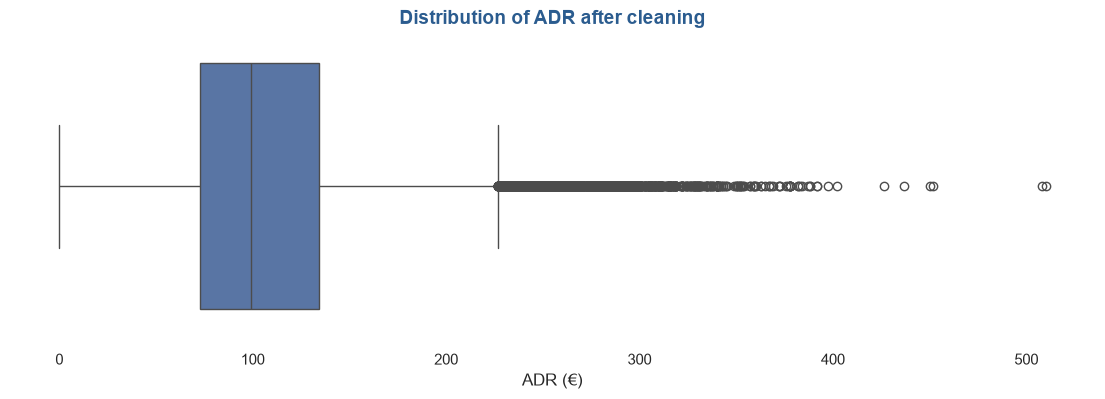

In [116]:
before = len(df)
df = df[(df['adr'] >= 0) & (df['adr'] < 5400)].reset_index(drop=True)
print(f'Removed {before - len(df)} rows with a wrong ADR')

sns.boxplot(x=df['adr'])
plt.title('Distribution of ADR after cleaning', weight='bold', color='#2B5C8F', size=14)
plt.xlabel('ADR (€)')
plt.grid(False)
sns.despine(left=True, bottom=True)
plt.show()

After cleaning, the middle 50% of bookings have an ADR between about €73 and €134, and the median is €99. A few higher prices (up to about €510) remain. I keep them as valid high-price bookings.

**Cleaning summary**

| Step | Rows removed | Rows left |
|---|---|---|
| Original data | | 119,390 |
| Exact duplicates | 31,994 | 87,396 |
| Zero guests | 166 | 87,230 |
| Zero nights and zero price | 591 | 86,639 |
| Wrong ADR (negative or 5,400) | 2 | **86,637** |

About 27% of the rows were removed, almost all of them as duplicates.

**Step 1.6. Create new columns.** These columns make the analysis easier.

In [117]:
# Make months ordered (January to December), so tables and charts do not sort them A-Z
month_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July',
               'August', 'September', 'October', 'November', 'December']
df['arrival_date_month'] = pd.Categorical(df['arrival_date_month'], categories=month_order, ordered=True)

# Day of the week of arrival
arrival_date = pd.to_datetime(
    df['arrival_date_year'].astype(str) + '-' +
    df['arrival_date_month'].astype(str) + '-' +
    df['arrival_date_day_of_month'].astype(str)
)
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
df['arrival_day'] = pd.Categorical(arrival_date.dt.day_name(), categories=days_order, ordered=True)

# Numbers
df['total_guests'] = df['adults'] + df['children'] + df['babies']
df['total_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']
df['total_revenue'] = df['adr'] * df['total_nights']                 # estimate: price x nights
df['lost_revenue'] = np.where(df['is_canceled'] == 1, df['total_revenue'], 0)
df['canceled_pct'] = df['is_canceled'] * 100                         # makes "mean" = cancellation rate in %

# Text labels (for readable charts)
df['status'] = np.where(df['is_canceled'] == 1, 'Canceled', 'Not canceled')
df['room_status'] = np.where(df['reserved_room_type'] != df['assigned_room_type'], 'Room changed', 'As reserved')
df['guest_type'] = np.where(df['is_repeated_guest'] == 1, 'Repeated guest', 'First-time guest')
df['has_children'] = np.where(df['children'] + df['babies'] > 0, 'With children', 'No children')
df['has_special_requests'] = np.where(df['total_of_special_requests'] > 0, 'With requests', 'No requests')

df[['total_guests', 'total_nights', 'total_revenue', 'status', 'room_status', 'arrival_day']].head()

,total_guests,total_nights,total_revenue,status,room_status,arrival_day
0,1,1,75.0,Not canceled,Room changed,Wednesday
1,1,1,75.0,Not canceled,As reserved,Wednesday
2,2,2,196.0,Not canceled,As reserved,Wednesday
3,2,2,214.0,Not canceled,As reserved,Wednesday
4,2,2,206.0,Not canceled,As reserved,Wednesday


### <b> 2. Cancellation Analysis </b>

#### <b> 2.1 Hotel type </b>

**Question:** How many bookings are canceled, and is it different for the City Hotel and the Resort Hotel?

**Method:** I count bookings and calculate the cancellation rate (canceled bookings ÷ all bookings) for each hotel. I also estimate the revenue in canceled bookings.

In [118]:
overall_rate = df['canceled_pct'].mean()
print(f'{overall_rate:.2f}% of all bookings are canceled.')

hotel_cancellations = df.groupby('hotel').agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum'),
    cancellation_rate=('canceled_pct', 'mean'),
    lost_revenue=('lost_revenue', 'sum')
).round(2)
hotel_cancellations

27.68% of all bookings are canceled.


,total_bookings,canceled_bookings,cancellation_rate,lost_revenue
hotel,,,,
City Hotel,53042,16021,30.20,6609055.63
Resort Hotel,33595,7964,23.71,4869587.35


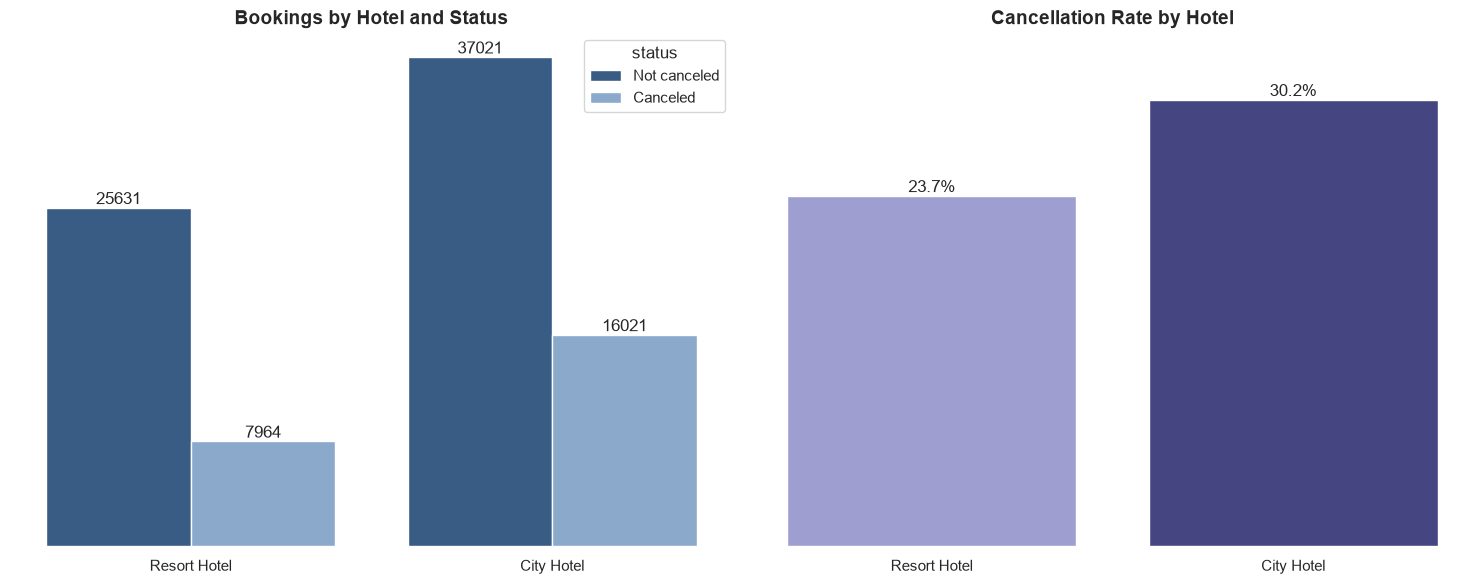

In [119]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
order = ['Resort Hotel', 'City Hotel']

sns.countplot(data=df, x='hotel', hue='status', palette=['#2B5C8F', '#7FA9D6'], ax=axes[0])
axes[0].set(title='Bookings by Hotel and Status', xlabel='', ylabel='')
for c in axes[0].containers:
    axes[0].bar_label(c)

sns.barplot(data=hotel_cancellations.reset_index(), x='hotel', y='cancellation_rate',
            hue='hotel', legend=False, order=order, palette=['#3B3B8C', '#9595D9'], ax=axes[1])
axes[1].set(title='Cancellation Rate by Hotel', xlabel='', ylabel='')
for c in axes[1].containers:
    axes[1].bar_label(c, fmt='%.1f%%')
axes[1].margins(y=0.15)

for ax in axes:
    ax.title.set_weight('bold')
    ax.title.set_size(14)
    ax.grid(False)
    ax.set_yticks([])

plt.tight_layout()
sns.despine(left=True, bottom=True)
plt.show()

In [120]:
canceled_money = df['lost_revenue'].sum()
all_money = df['total_revenue'].sum()
print(f'Estimated revenue in canceled bookings: €{canceled_money:,.0f}')
print(f'Share of all booked revenue: {canceled_money / all_money * 100:.1f}%')

Estimated revenue in canceled bookings: €11,478,643
Share of all booked revenue: 33.3%


**Insights**

- The **City Hotel** has more bookings (53,042 vs 33,595) and a higher cancellation rate: **30.2%** vs **23.7%** in the Resort Hotel.
- About **one third (33.3%)** of all booked room revenue is in canceled bookings (about €11.5 million). This share is higher than the share of canceled bookings (27.7%). So canceled bookings are worth *more* than the average booking.
- This revenue is an estimate. The data does not show if the hotel kept any payment or sold the room again.
- A possible reason for the difference between hotels: city guests often travel for short trips or business, and they change plans more easily. Resort guests plan a vacation, so they commit more. The data cannot prove this.

**Next step:** I look at lead time (how many days before arrival the guest books).

#### <b> 2.2 Lead time </b>

**Question:** Do guests who book earlier cancel more often?

**Method:** First I compare the average and median lead time of canceled and not canceled bookings. Then I put bookings into five lead time groups and calculate the cancellation rate in each group.

In [121]:
df.groupby('status')['lead_time'].agg(['mean', 'median', 'count']).round(1)

,mean,median,count
status,,,
Canceled,105.8,80.0,23985
Not canceled,70.5,38.0,62652


In [122]:
df['lead_time_group'] = pd.cut(
    df['lead_time'],
    bins=[0, 7, 30, 90, 180, float('inf')],
    labels=['0-7 days', '8-30 days', '31-90 days', '91-180 days', '180+ days'],
    include_lowest=True
)

lead_time_cancellations = df.groupby('lead_time_group', observed=False).agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum'),
    cancellation_rate=('canceled_pct', 'mean')
).round(2).reset_index()
lead_time_cancellations

,lead_time_group,total_bookings,canceled_bookings,cancellation_rate
0,0-7 days,17855,1520,8.51
1,8-30 days,16234,4139,25.50
2,31-90 days,22633,7275,32.14
3,91-180 days,18190,6379,35.07
4,180+ days,11725,4672,39.85


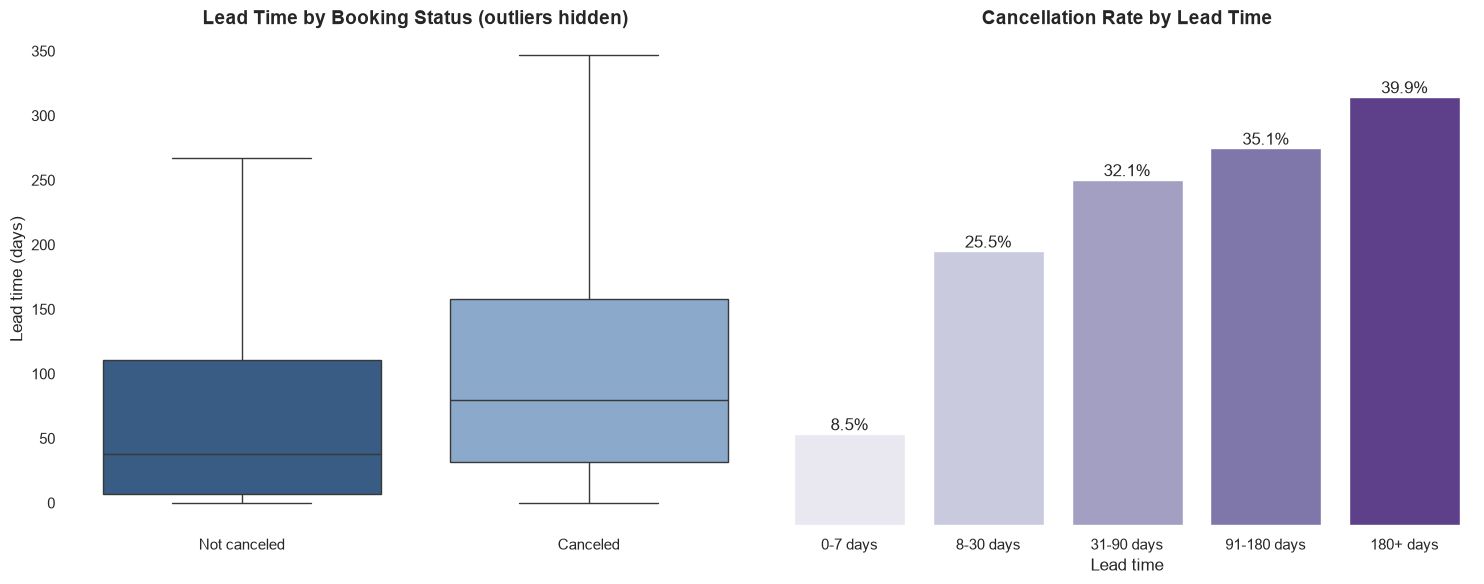

In [123]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.boxplot(data=df, x='status', y='lead_time', hue='status', legend=False, showfliers=False, palette=['#2B5C8F', '#7FA9D6'], ax=axes[0])
axes[0].set(title='Lead Time by Booking Status (outliers hidden)', xlabel='', ylabel='Lead time (days)')

sns.barplot(data=lead_time_cancellations, x='lead_time_group', y='cancellation_rate',
            hue='lead_time_group', legend=False, dodge=False, palette='Purples', ax=axes[1])
axes[1].set(title='Cancellation Rate by Lead Time', xlabel='Lead time', ylabel='')
for c in axes[1].containers:
    axes[1].bar_label(c, fmt='%.1f%%')
axes[1].margins(y=0.15)
axes[1].set_yticks([])

for ax in axes:
    ax.title.set_weight('bold')
    ax.title.set_size(14)
    ax.grid(False)

plt.tight_layout()
sns.despine(left=True, bottom=True)
plt.show()

**Insights**

- The cancellation rate goes up when the lead time is longer: **8.5%** for bookings made 0–7 days before arrival, and **39.9%** for bookings made more than 180 days before.
- The median lead time of canceled bookings is **80 days**, more than double the median of kept bookings (**38 days**).
- The biggest jump is between the first and second group (8.5% → 25.5%). After one week, the risk is already much higher.
- **Idea for a hotel:** use stricter conditions (a partial prepayment or a non-refundable rate with a discount) for bookings made far in advance, and keep flexible conditions for last-minute bookings, which almost always arrive.

#### <b> 2.3 Market segment </b>

**Question:** Do some booking channels cancel more than others?

**Method:** For each market segment I count bookings and calculate the cancellation rate. I leave out the segment "Undefined" in the chart (only 2 bookings).

In [124]:
segment_cancellations = df.groupby('market_segment').agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum'),
    cancellation_rate=('canceled_pct', 'mean')
).sort_values('total_bookings', ascending=False).round(2).reset_index()
segment_cancellations

,market_segment,total_bookings,canceled_bookings,cancellation_rate
0,Online TA,51285,18230,35.55
1,Offline TA/TO,13748,2055,14.95
2,Direct,11652,1733,14.87
3,Groups,4891,1331,27.21
4,Corporate,4155,507,12.20
5,Complementary,682,83,12.17
6,Aviation,222,44,19.82
7,Undefined,2,2,100.00


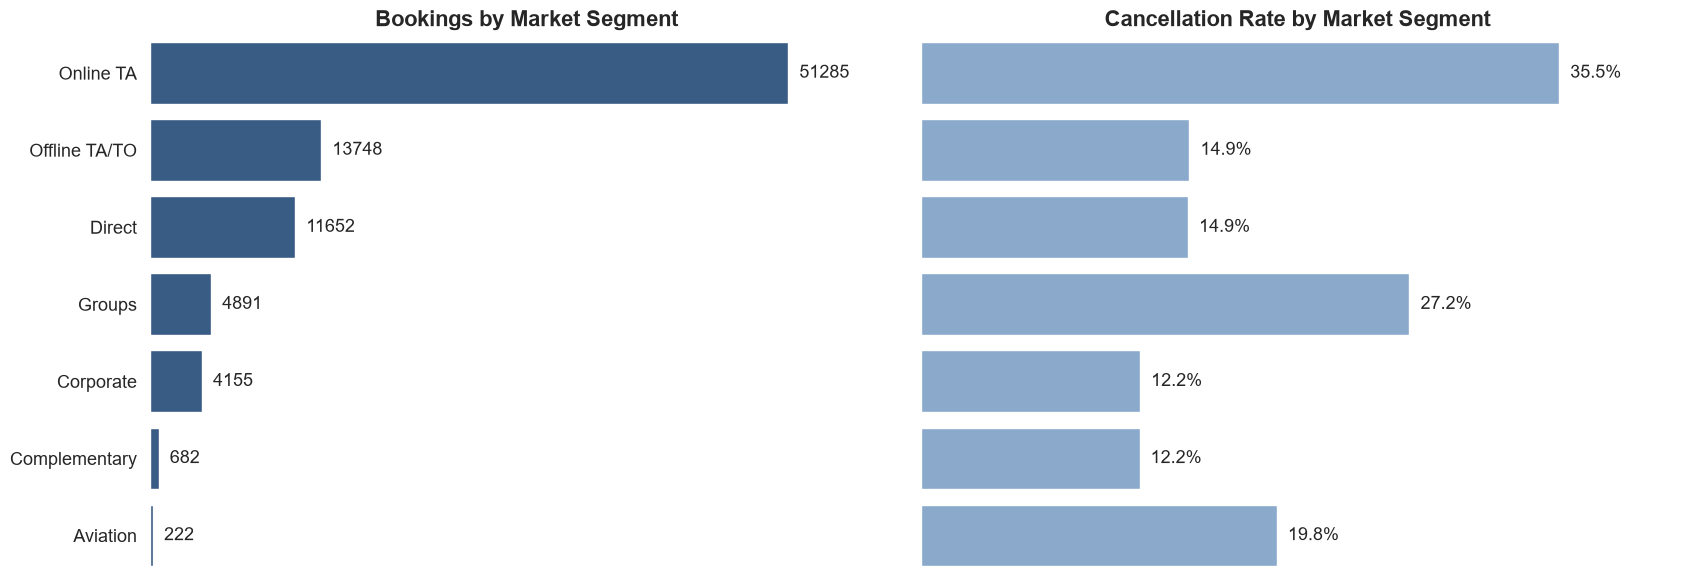

In [125]:
seg_plot = segment_cancellations[segment_cancellations['total_bookings'] > 10]

fig, axes = plt.subplots(1, 2, figsize=(17, 6), sharey=True)

sns.barplot(data=seg_plot, y='market_segment', x='total_bookings', color='#2B5C8F', ax=axes[0])
axes[0].set(title='Bookings by Market Segment', xlabel='', ylabel='')
axes[0].bar_label(axes[0].containers[0], fmt='%d', padding=8, fontsize=13)

sns.barplot(data=seg_plot, y='market_segment', x='cancellation_rate', color='#7FA9D6', ax=axes[1])
axes[1].set(title='Cancellation Rate by Market Segment', xlabel='', ylabel='')
axes[1].bar_label(axes[1].containers[0], fmt='%.1f%%', padding=8, fontsize=13)

for ax in axes:
    ax.title.set_weight('bold')
    ax.title.set_size(16)
    ax.tick_params(axis='both', labelsize=13)
    ax.margins(x=0.18)
    ax.grid(False)
    ax.set_xticks([])

plt.tight_layout()
sns.despine(left=True, bottom=True)
plt.show()

**Insights**

- **Online TA** (online travel agencies) is the biggest channel: **51,285 bookings, 59% of all bookings**. It also has the highest cancellation rate: **35.6%**.
- **Direct** (14.9%), **Offline TA/TO** (15.0%) and **Corporate** (12.2%) cancel much less. Online TA cancels about **2.4 times more** than Direct.
- **Groups** are in the middle to high range (27.2%).
- A possible reason for Online TA: guests can often cancel for free, and some book several hotels at the same time and decide later. The data does not show this directly.

#### <b> 2.4 Segment and lead time together </b>

**Question:** The two factors above (channel and lead time) may work together. Where is the cancellation risk the highest?

**Method:** I calculate the cancellation rate for every combination of market segment and lead time group, and show it as a heatmap. I also print the number of bookings in each cell, because a rate based on very few bookings is not reliable.

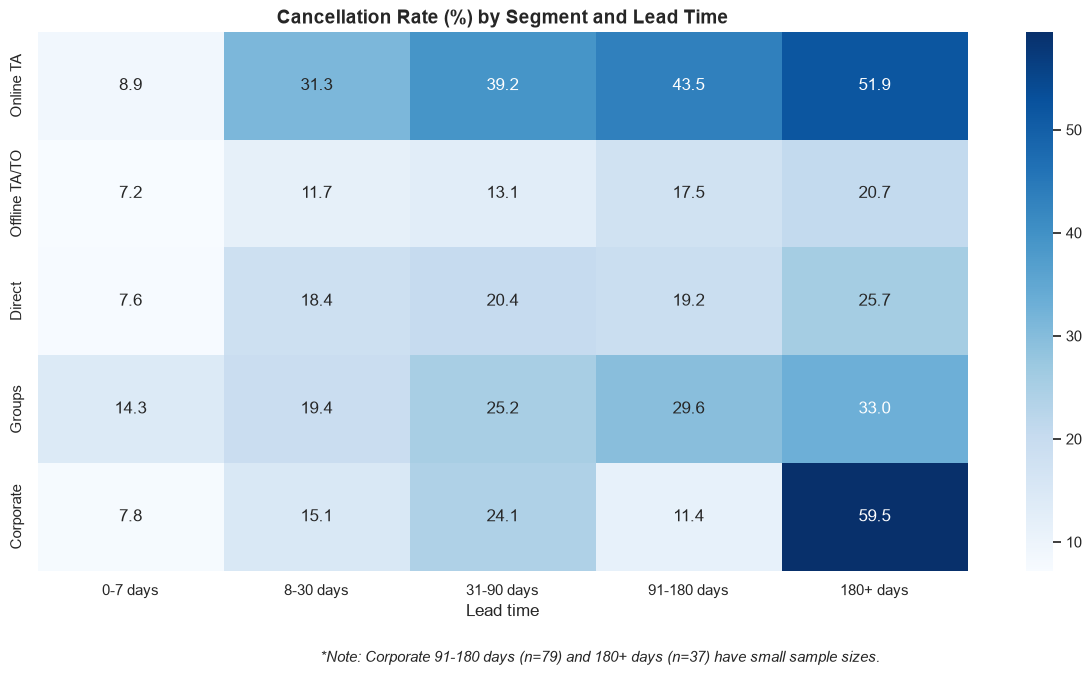

lead_time_group,0-7 days,8-30 days,31-90 days,91-180 days,180+ days
market_segment,,,,,
Online TA,7803,10218,15188,11761,6315
Offline TA/TO,1615,2005,3607,3739,2782
Direct,4882,2128,2212,1653,777
Groups,441,649,1050,941,1810
Corporate,2472,1057,510,79,37


In [126]:
main_segments = ['Online TA', 'Offline TA/TO', 'Direct', 'Groups', 'Corporate']
main = df[df['market_segment'].isin(main_segments)]

risk_rate = main.pivot_table(index='market_segment', columns='lead_time_group',
                             values='canceled_pct', aggfunc='mean', observed=False).round(1)
risk_count = main.pivot_table(index='market_segment', columns='lead_time_group',
                              values='canceled_pct', aggfunc='count', observed=False)

plt.figure(figsize=(15, 7))
sns.heatmap(risk_rate.loc[main_segments], annot=True, fmt='.1f', cmap='Blues')
plt.title('Cancellation Rate (%) by Segment and Lead Time',  weight='bold', size=14)
plt.xlabel('Lead time')
plt.ylabel('')
plt.figtext(0.5, -0.02, '*Note: Corporate 91-180 days (n=79) and 180+ days (n=37) have small sample sizes.', ha='center', fontsize=11, style='italic')
plt.show()

risk_count.loc[main_segments]

**Insights**

- **Online TA with a long lead time is the highest-risk group:** **43.5%** for bookings made 91–180 days before arrival and **51.9%** for 180+ days. Even the 8–30 days group has a rate of 31.3%.
- Online TA bookings made more than 90 days before arrival are about **18,000 bookings (21% of all bookings)**, with a cancellation rate of about **46%**. They give roughly **one third of all cancellations**.
- **Lead time alone is not the problem; the channel matters too.** Offline TA/TO bookings with the same long lead time (180+ days) cancel only **20.7%**, and Direct bookings **25.7%**.
- **Groups** grow steadily with lead time, from 14.3% to 33.0%.
- **Corporate** shows 59.5% in the 180+ group, but this group has only **37 bookings** (and 79 in the 91–180 group), so the rate is not reliable. I do not use it for conclusions.

#### <b> 2.5 Deposit type </b>

**Question:** Does the deposit policy protect the hotel from cancellations?

**Method:** I calculate the cancellation rate for each deposit type: No Deposit, Non Refund and Refundable. Then I check which market segments use "Non Refund".

In [127]:
deposit_cancellations = df.groupby('deposit_type').agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum'),
    cancellation_rate=('canceled_pct', 'mean')
).sort_values('total_bookings', ascending=False).round(2).reset_index()
deposit_cancellations

,deposit_type,total_bookings,canceled_bookings,cancellation_rate
0,No Deposit,85493,22977,26.88
1,Non Refund,1037,982,94.70
2,Refundable,107,26,24.30


In [128]:
pd.crosstab(df['deposit_type'], df['market_segment'])

market_segment,Aviation,Complementary,Corporate,Direct,Groups,Offline TA/TO,Online TA,Undefined
deposit_type,,,,,,,,
No Deposit,222,682,4088,11636,4152,13458,51253,2
Non Refund,0,0,64,10,659,286,18,0
Refundable,0,0,3,6,80,4,14,0


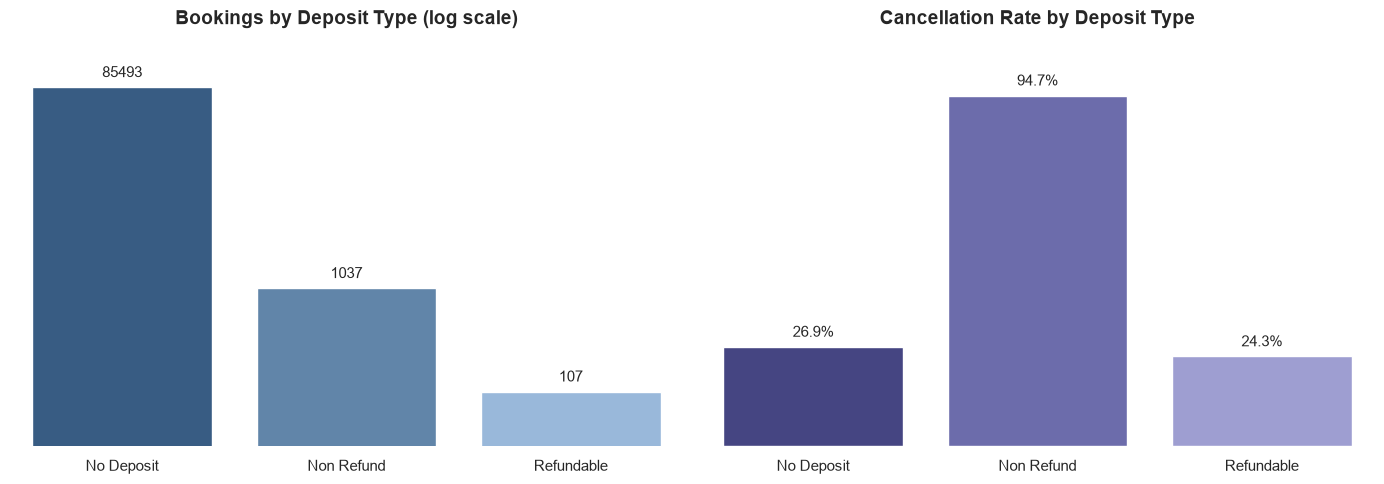

In [129]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors_1 = ['#2B5C8F', '#5585B5', '#8EB8E5']
colors_2 = ['#3B3B8C', '#6262B5', '#9595D9']
          
sns.barplot(data=deposit_cancellations, x='deposit_type', y='total_bookings',
            hue='deposit_type', legend=False, palette=colors_1, ax=axes[0])
axes[0].set(title='Bookings by Deposit Type (log scale)', xlabel='', ylabel='')
axes[0].set_yscale('log')

sns.barplot(data=deposit_cancellations, x='deposit_type', y='cancellation_rate',
            hue='deposit_type', legend=False, palette=colors_2, ax=axes[1])
axes[1].set(title='Cancellation Rate by Deposit Type', xlabel='', ylabel='')



for ax in axes:
    fmt = '%d' if ax == axes[0] else '%.1f%%' 
    for c in ax.containers: 
        ax.bar_label(c, fmt=fmt, padding=5, fontsize=11)
    ax.title.set_weight('bold')
    ax.title.set_size(14)
    ax.margins(y=0.18)
    ax.grid(False)
    ax.set_yticks([])

plt.tight_layout()
sns.despine(left=True, bottom=True)
plt.show()

**Insights**

- This result looks strange: **Non Refund** bookings have a cancellation rate of **94.7%** (982 of 1,037), compared with 26.9% for No Deposit and 24.3% for Refundable. One would expect the opposite.
- The table of segments gives a clue: **91% of Non Refund bookings (945 of 1,037) come from Groups (659) and Offline TA/TO (286)**. Only 18 come from Online TA. A possible explanation is that tour operators block many rooms early under a non-refundable contract and later release the rooms they do not sell. This is only a guess, because the data does not show contracts.
- Non Refund is small: only **1.2%** of all bookings. Most cancellations (**96%**, 22,977 of 23,985) come from **No Deposit** bookings. This is where the hotel can improve the most.
- **Important limit:** the data does not show if the hotel kept the money from Non Refund bookings. So I cannot say if these cancellations cost the hotel anything.
- **Idea for a hotel:** check the contract rules with tour operators and groups (for example, the date when unsold rooms are released), and test partial deposits for risky No Deposit bookings, such as Online TA with a long lead time.

#### <b> 2.6 Repeated guests and special requests </b>

**Question:** Do loyal guests, and guests who talk to the hotel before arrival, cancel less?

**Method:** I compare the cancellation rate of first-time and repeated guests. Then I group bookings by the number of special requests (0, 1, 2, 3 or more) and compare the rates.

In [130]:
guests_cancellations = df.groupby('guest_type').agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum'),
    cancellation_rate=('canceled_pct', 'mean')
).round(2).reset_index()
guests_cancellations

,guest_type,total_bookings,canceled_bookings,cancellation_rate
0,First-time guest,83493,23726,28.42
1,Repeated guest,3144,259,8.24


In [131]:
df['special_requests_group'] = np.where(
    df['total_of_special_requests'] >= 3, '3+', df['total_of_special_requests'].astype(str)
)

requests_cancellations = df.groupby('special_requests_group').agg(
    total_bookings=('is_canceled', 'count'),
    canceled_bookings=('is_canceled', 'sum'),
    cancellation_rate=('canceled_pct', 'mean')
).round(2).reset_index()
requests_cancellations

,special_requests_group,total_bookings,canceled_bookings,cancellation_rate
0,0,43431,14547,33.49
1,1,28804,6492,22.54
2,2,11739,2514,21.42
3,3+,2663,432,16.22


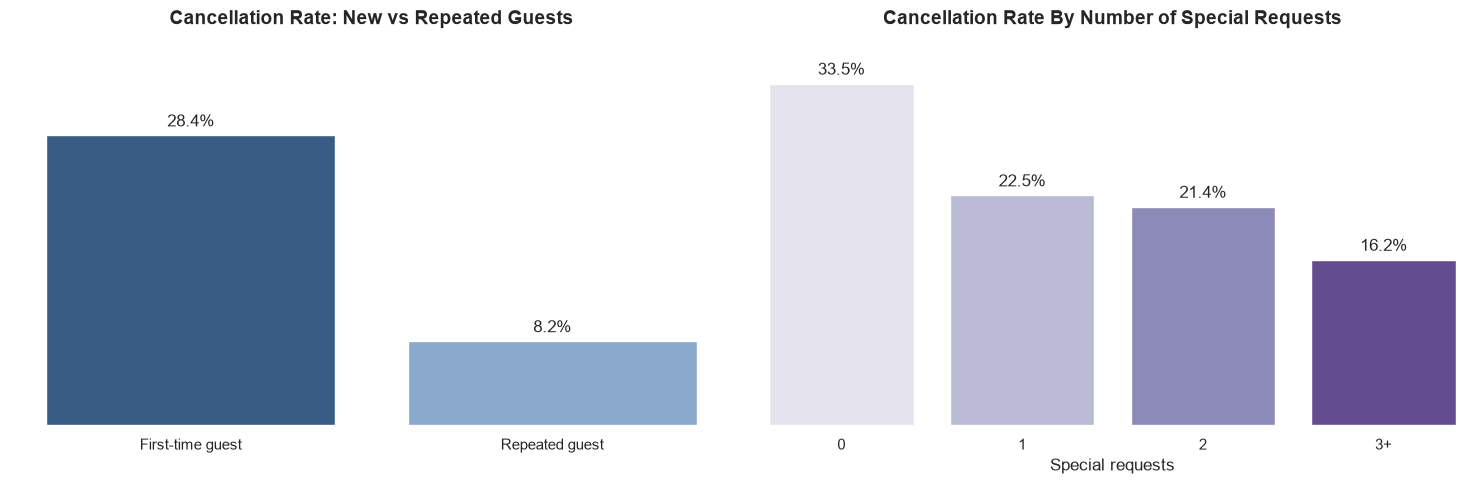

In [132]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)

sns.barplot(data=guests_cancellations, x='guest_type', y='cancellation_rate',
            hue='guest_type', legend=False, palette=['#2B5C8F', '#7FA9D6'], ax=axes[0])
axes[0].set(title='Cancellation Rate: New vs Repeated Guests', xlabel='', ylabel='')

sns.barplot(data=requests_cancellations, x='special_requests_group', y='cancellation_rate',
            hue='special_requests_group', legend=False, palette='Purples', ax=axes[1])
axes[1].set(title='Cancellation Rate By Number of Special Requests', xlabel='Special requests', ylabel='')


for ax in axes:
    for c in ax.containers:
        ax.bar_label(c, fmt='%.1f%%', padding=4)
    ax.title.set_weight('bold')
    ax.title.set_size(14)
    ax.margins(y=0.15)
    ax.grid(False)
    ax.set_yticks([])

plt.tight_layout()
sns.despine(left=True, bottom=True)
plt.show()

**Insights**

- **Repeated guests** cancel **3.4 times less** than first-time guests (**8.2%** vs **28.4%**). But they are only 3,144 bookings (3.6% of the total), and many of them book with Corporate rates (see section 4.2), so part of the difference may come from the booking type and not only from loyalty.
- The more **special requests** a booking has, the lower the cancellation rate: **33.5%** (0 requests), **22.5%** (1), **21.4%** (2), **16.2%** (3 or more).
- This is a link, not proof of a cause. One more detail: a guest can add a request after booking, so guests who cancel early have less time to add one. Part of the link may come from this.

### <b> 3. Seasonality and Price Dynamics </b>

For this part I use only **confirmed bookings** (not canceled), because I want to see real guests and real prices.

**An important check before the charts.** The dataset does not cover the same number of months in each year. Let me count the months in each year.

In [133]:
df_confirmed = df[df['is_canceled'] == 0]
df.groupby('arrival_date_year')['arrival_date_month'].nunique()

arrival_date_year
2015     6
2016    12
2017     8
Name: arrival_date_month, dtype: int64

2015 has only 6 months (July–December), 2016 has all 12 months, and 2017 has 8 months (January–August). This means July and August appear in **three** years, but other months in only **two**. If I add up the guests for all years, summer would look busier just because it has one more year of data.

To avoid this, in this section I use **only 2016**, the only full year. The limit is that this shows one year, so I cannot say if the pattern repeats every year.

#### <b> 3.1 Guests and ADR by month (2016) </b>

**Question:** In which months are there more guests, and when are prices high?

**Method:** I take confirmed bookings from 2016. I sum the guests by arrival month and calculate the average ADR by month for each hotel.

In [134]:
df_2016 = df_confirmed[df_confirmed['arrival_date_year'] == 2016]

guests_by_month = df_2016.pivot_table(index='arrival_date_month', columns='hotel',
                                      values='total_guests', aggfunc='sum', observed=False)
adr_by_month = df_2016.pivot_table(index='arrival_date_month', columns='hotel',
                                   values='adr', aggfunc='mean', observed=False).round(2)

display(guests_by_month)
display(adr_by_month)

hotel,City Hotel,Resort Hotel
arrival_date_month,,
January,1393,1247
February,2404,1806
March,3321,2263
April,3333,1955
May,3220,2144
June,3181,1869
July,4099,2126
August,4386,2480
September,3527,1928


hotel,City Hotel,Resort Hotel
arrival_date_month,,
January,75.81,46.42
February,84.15,51.21
March,89.26,56.29
April,101.48,67.83
May,114.59,73.27
June,109.92,101.50
July,117.64,156.21
August,124.82,190.41
September,124.44,107.85


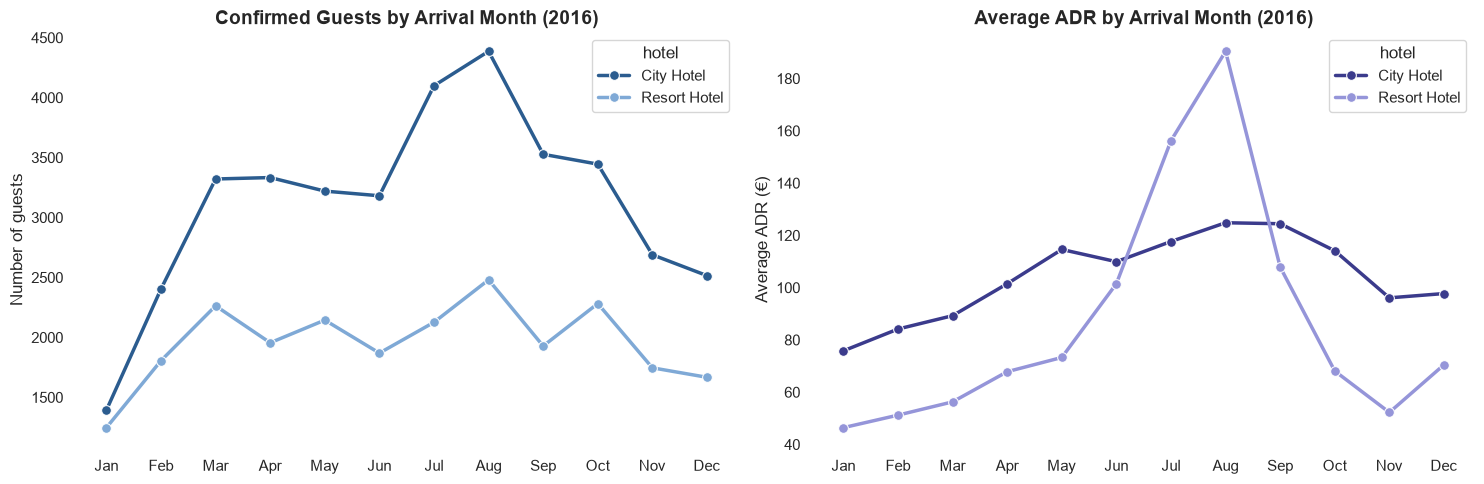

In [135]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Short month names (Jan, Feb, ...) for the chart
sns.lineplot(data=guests_by_month.rename(index=lambda m: m[:3]), marker='o', dashes=False, palette=['#2B5C8F', '#7FA9D6'], linewidth=2.5, markersize=7, ax=axes[0])
axes[0].set(title='Confirmed Guests by Arrival Month (2016)', xlabel='', ylabel='Number of guests')

sns.lineplot(data=adr_by_month.rename(index=lambda m: m[:3]), marker='o', dashes=False, palette=['#3B3B8C', '#9595D9'], linewidth=2.5, markersize=7, ax=axes[1])
axes[1].set(title='Average ADR by Arrival Month (2016)', xlabel='', ylabel='Average ADR (€)')

for ax in axes:
    ax.title.set_weight('bold')
    ax.title.set_size(14)
    ax.grid(False)

plt.tight_layout()
sns.despine(left=True, bottom=True)
plt.show()

**Insights**

- **Guests:** Both hotels have the most guests in **August** (City Hotel 4,386; Resort Hotel 2,480) and the fewest in **January** (1,393 and 1,247). The City Hotel is busy from March to October (about 3,200 to 4,400 guests a month). The Resort Hotel has between about 1,700 and 2,500 guests in all months except January, so the summer peak is smaller than I expected.
- **Prices:** The Resort Hotel changes prices a lot: ADR goes from **€46 in January to €190 in August** (about 4 times higher). The City Hotel is calmer: from €76 in January to €125 in August.
- **Resort vs City:** The Resort Hotel is more expensive than the City Hotel only in **July (€156 vs €118) and August (€190 vs €125)**. In all other months it is cheaper.
- **What this means:** The Resort Hotel's summer income depends mostly on **price**, not on many more guests. That is a pricing strategy a revenue manager can use.
- **Limit:** One year of data (2016). Guests are counted in the month of arrival, even if the stay continues into the next month.

#### <b> 3.2 Families and length of stay </b>

**Question:** Do guests with children bring more revenue? On which arrival days do guests stay longer?

**Method:** For confirmed bookings I compare the average ADR and the average revenue per booking for guests with and without children. Then I calculate the average number of nights by arrival day of the week.

In [136]:
children_table = df_confirmed.pivot_table(index='hotel', columns='has_children',
                                          values=['adr', 'total_revenue'], aggfunc='mean').round(2)
children_table

adr               total_revenue              
has_children No children With children   No children With children
hotel                                                             
City Hotel        105.32        147.63        315.62        450.02
Resort Hotel       87.92        153.58        391.62        705.82

In [137]:
nights_by_day = df_confirmed.pivot_table(index='arrival_day', columns='hotel',
                                         values='total_nights', aggfunc='mean', observed=False).round(2)
nights_by_day

hotel,City Hotel,Resort Hotel
arrival_day,,
Monday,3.17,4.48
Tuesday,2.94,4.14
Wednesday,2.83,3.79
Thursday,2.88,4.32
Friday,2.74,3.73
Saturday,3.05,4.37
Sunday,3.41,4.92


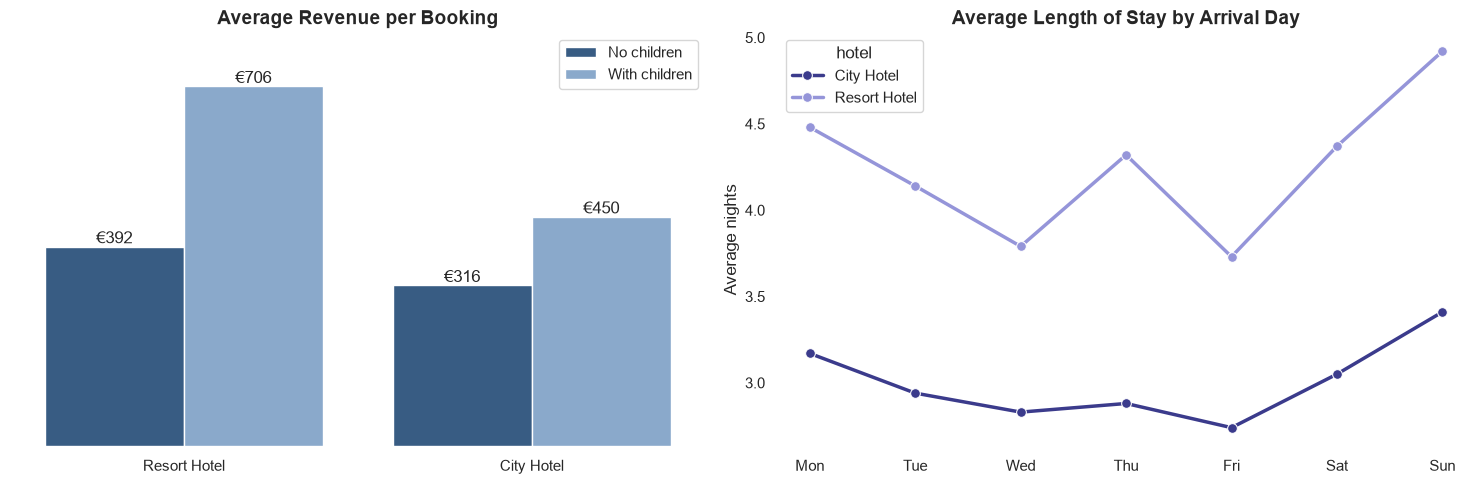

In [138]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(data=df_confirmed, x='hotel', y='total_revenue', hue='has_children', errorbar=None, palette=['#2B5C8F', '#7FA9D6'], ax=axes[0])
axes[0].set(title='Average Revenue per Booking', xlabel='', ylabel='')
axes[0].legend(title='')
for c in axes[0].containers:
    axes[0].bar_label(c, fmt='€%.0f')
axes[0].margins(y=0.15)
axes[0].set_yticks([])

sns.lineplot(data=nights_by_day.rename(index=lambda d: d[:3]), marker='o', dashes=False, palette=['#3B3B8C', '#9595D9'], linewidth=2.5, markersize=7, ax=axes[1])
axes[1].set(title='Average Length of Stay by Arrival Day', xlabel='', ylabel='Average nights')

for ax in axes:
    ax.title.set_weight('bold')
    ax.title.set_size(14)
    ax.grid(False)

plt.tight_layout()
sns.despine(left=True, bottom=True)
plt.show()

**Insights**

- **Families bring more revenue.** The average revenue per booking is **€450 vs €316** in the City Hotel (+43%) and **€706 vs €392** in the Resort Hotel (+80%). Part of the reason is a higher ADR (families probably book bigger rooms), and part is longer stays.
- **Length of stay by arrival day:** Guests who arrive on **Sunday** stay the longest (City Hotel 3.4 nights; Resort Hotel 4.9 nights), followed by Monday. Guests who arrive on **Friday** stay the shortest (2.7 and 3.7 nights).
- The differences between days are not very big (about 0.7 nights in the City Hotel), so I would not build a big strategy on this alone.

### <b> 4. Operations and Repeated Guests

#### 4.1 Room changes </b>

**Question:** How often does the hotel give the guest a different room type than the one reserved? Does this connect to cancellations?

**Method:** I compare `reserved_room_type` and `assigned_room_type` and calculate the share of changed rooms and the cancellation rate for both groups.

In [139]:
room_change = df.groupby(['hotel', 'room_status']).agg(
    bookings=('is_canceled', 'count'),
    cancellation_rate=('canceled_pct', 'mean')
).round(2)
room_change['share_in_hotel'] = (room_change['bookings'] / room_change.groupby('hotel')['bookings'].transform('sum') * 100).round(1)
room_change

bookings  cancellation_rate  share_in_hotel
hotel        room_status                                              
City Hotel   As reserved      47171              33.31            88.9
             Room changed      5871               5.26            11.1
Resort Hotel As reserved      26806              28.59            79.8
             Room changed      6789               4.40            20.2

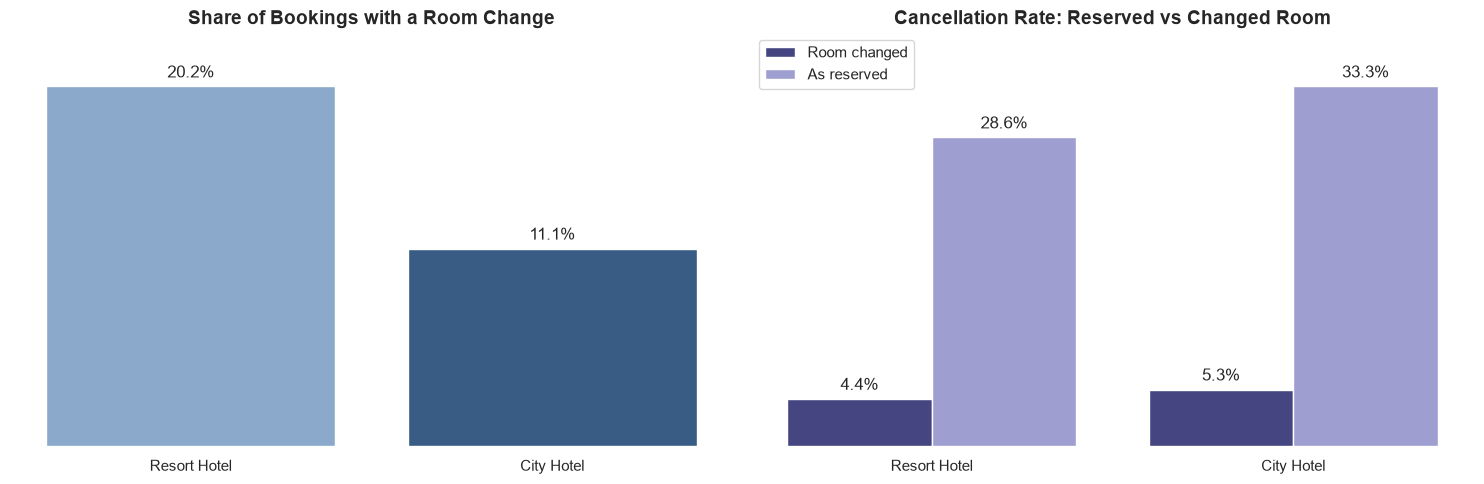

In [140]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
order = ['Resort Hotel', 'City Hotel']

changed_share = room_change.reset_index().query("room_status == 'Room changed'")
sns.barplot(data=changed_share, x='hotel', y='share_in_hotel', hue='hotel', legend=False, order=order, palette=['#2B5C8F', '#7FA9D6'], ax=axes[0])
axes[0].set(title='Share of Bookings with a Room Change', xlabel='', ylabel='')


sns.barplot(data=df, x='hotel', y='canceled_pct', hue='room_status', errorbar=None, order=order, palette=['#3B3B8C', '#9595D9'], ax=axes[1])
axes[1].set(title='Cancellation Rate: Reserved vs Changed Room', xlabel='', ylabel='')
axes[1].legend(title='')


for ax in axes:
    for c in ax.containers:
        ax.bar_label(c, fmt='%.1f%%', padding=4)
    ax.title.set_weight('bold')
    ax.title.set_size(14)
    ax.margins(y=0.15)
    ax.grid(False)
    ax.set_yticks([])

plt.tight_layout()
sns.despine(left=True, bottom=True)
plt.show()

**Insights**

- The Resort Hotel gives a different room type almost **twice as often** (**20.2%** of bookings) as the City Hotel (**11.1%**).
- Bookings with a changed room have a very low cancellation rate (**4–5%**, against **29–33%** for rooms as reserved).
- **This is not a reason for fewer cancellations.** The room is assigned at check-in. A canceled booking never arrives, so it almost never gets a room change. The result comes from *how the data is recorded*. I will not use it as a recommendation.

#### <b> 4.2 Who are the repeated guests? </b>

**Question:** Repeated guests cancel less (section 2.6). Who are they, and how much do they pay?

**Method:** For each hotel I compare first-time and repeated guests (number of bookings, cancellation rate, average ADR), and I check which market segments repeated guests come from.

In [141]:
repeated_table = df.groupby(['hotel', 'guest_type']).agg(
    bookings=('is_canceled', 'count'),
    cancellation_rate=('canceled_pct', 'mean'),
    mean_adr=('adr', 'mean')
).round(2)
repeated_table

bookings  cancellation_rate  mean_adr
hotel        guest_type                                             
City Hotel   First-time guest     51500              30.75    112.87
             Repeated guest        1542              12.13     71.28
Resort Hotel First-time guest     31993              24.67    101.68
             Repeated guest        1602               4.49     69.07

In [142]:
repeated_segments = pd.crosstab(
    df.loc[df['is_repeated_guest'] == 1, 'market_segment'],
    df.loc[df['is_repeated_guest'] == 1, 'hotel'],
    normalize='columns'
).mul(100).round(1).sort_values(by='City Hotel')
repeated_segments

hotel,City Hotel,Resort Hotel
market_segment,,
Groups,1.4,1.9
Aviation,3.8,0.0
Offline TA/TO,5.4,8.1
Direct,9.5,34.5
Online TA,9.8,20.7
Complementary,12.8,1.1
Corporate,57.1,33.6


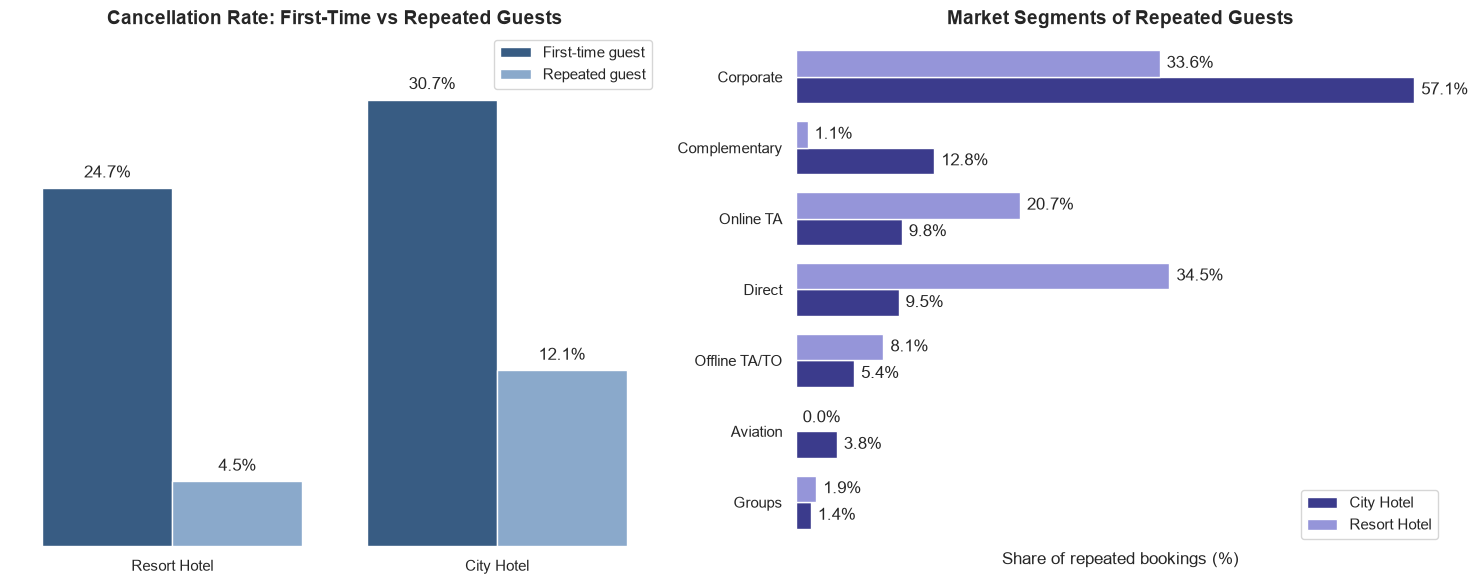

In [143]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.barplot(data=df, x='hotel', y='canceled_pct', hue='guest_type', errorbar=None, palette=['#2B5C8F', '#7FA9D6'], ax=axes[0])
axes[0].set(title='Cancellation Rate: First-Time vs Repeated Guests', xlabel='', ylabel='')
axes[0].legend(title='')
axes[0].set_yticks([])

repeated_segments.plot(kind='barh', color=['#3B3B8C', '#9595D9'], width=0.75, ax=axes[1])
axes[1].set(title='Market Segments of Repeated Guests', xlabel='Share of repeated bookings (%)', ylabel='')
axes[1].legend(title='')
axes[1].set_xticks([])

for ax in axes:
    for c in ax.containers:
        ax.bar_label(c, fmt='%.1f%%', padding=5)
    ax.title.set_weight('bold')
    ax.title.set_size(14)
    ax.grid(False)
    ax.margins(y=0.15)

plt.tight_layout()
sns.despine(left=True, bottom=True)
plt.show()

**Insights**

- Repeated guests are a small group (**2.9%** of bookings in the City Hotel, **4.8%** in the Resort Hotel), but they are reliable: the cancellation rate is **12.1% vs 30.8%** in the City Hotel and **4.5% vs 24.7%** in the Resort Hotel.
- Their ADR is **32–37% lower** (€71 vs €113 in the City Hotel; €69 vs €102 in the Resort Hotel).
- The reason is the channel mix: **57%** of repeated bookings in the City Hotel are **Corporate** (usually negotiated rates). In the Resort Hotel they come from **Direct** (34.5%) and Corporate (33.6%).
- So today loyalty is mostly business: repeated *leisure* guests, who could pay a full price, are rare.

### <b> 5. Trends Over the Years and Statistical Tests

#### 5.1 Trend 2015–2017 </b>

**Question:** Do prices and cancellations change from year to year?

**A problem with the simple way.** If I compare full years, the numbers are not fair: 2015 has only July–December, 2016 has 12 months and 2017 has January–August. Months have different prices and different cancellation levels, so the result mixes *time* and *season*. First I show the simple table, then the fair one.

In [144]:
# The simple way (not fair: different months in each year)
df.groupby(['hotel', 'arrival_date_year']).agg(
    bookings=('is_canceled', 'count'),
    cancellation_rate=('canceled_pct', 'mean'),
    mean_adr=('adr', 'mean')
).round(2)

bookings  cancellation_rate  mean_adr
hotel        arrival_date_year                                       
City Hotel   2015                   6480              21.91     90.78
             2016                  26548              29.28    108.51
             2017                  20014              34.12    122.60
Resort Hotel 2015                   6662              19.24     95.87
             2016                  15418              22.11     91.91
             2017                  11515              28.42    113.58

This table is misleading. For example, the Resort Hotel ADR looks lower in 2016 than in 2015, but this is only because 2015 has no cheap winter months.

**The fair way:** I compare the **same months in each year**. July and August exist in all three years, so I use them. For ADR I use confirmed bookings only.

In [145]:
summer = df[df['arrival_date_month'].isin(['July', 'August'])]

summer_trend = summer.groupby(['hotel', 'arrival_date_year']).agg(
    bookings=('is_canceled', 'count'),
    cancellation_rate=('canceled_pct', 'mean')
)
summer_trend['mean_adr'] = summer[summer['is_canceled'] == 0].groupby(['hotel', 'arrival_date_year'])['adr'].mean()
summer_trend = summer_trend.round(2).reset_index()
summer_trend

,hotel,arrival_date_year,bookings,cancellation_rate,mean_adr
0,City Hotel,2015,1488,30.98,81.59
1,City Hotel,2016,5267,30.11,121.33
2,City Hotel,2017,5520,35.47,134.36
3,Resort Hotel,2015,2592,24.00,142.08
4,Resort Hotel,2016,2946,32.01,174.35
5,Resort Hotel,2017,3369,37.01,188.39


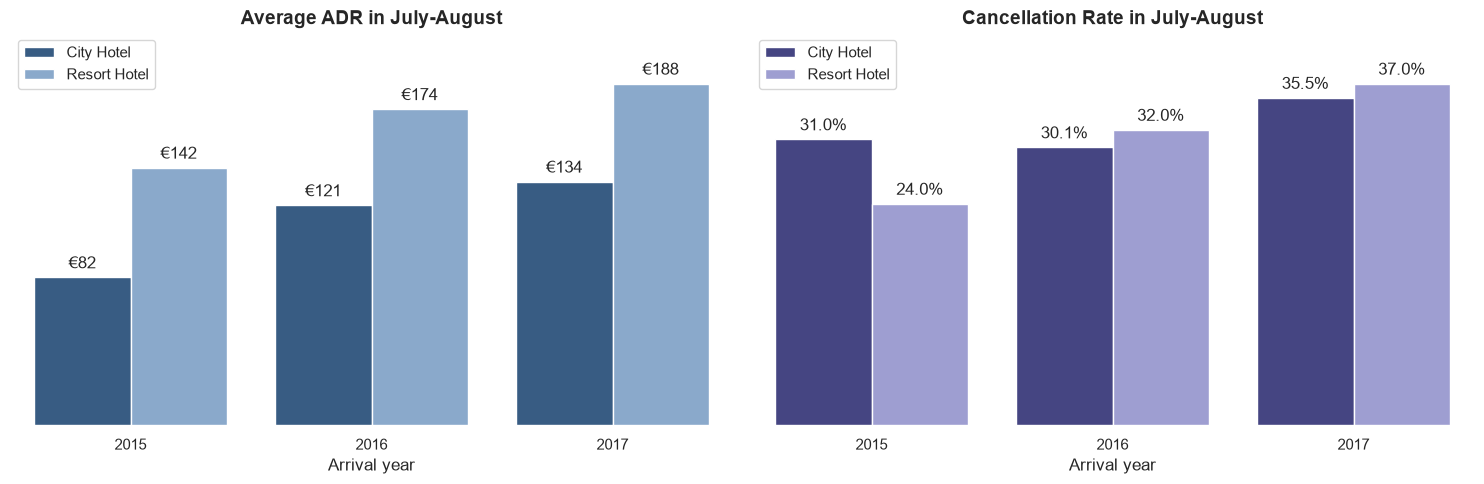

In [146]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(data=summer_trend, x='arrival_date_year', y='mean_adr', hue='hotel', palette=['#2B5C8F', '#7FA9D6'], ax=axes[0])
axes[0].set(title='Average ADR in July-August', xlabel='Arrival year', ylabel='')
axes[0].legend(title='')
for c in axes[0].containers:
    axes[0].bar_label(c, fmt='€%.0f', padding=4)

sns.barplot(data=summer_trend, x='arrival_date_year', y='cancellation_rate', hue='hotel', palette=['#3B3B8C', '#9595D9'], ax=axes[1])
axes[1].set(title='Cancellation Rate in July-August', xlabel='Arrival year', ylabel='')
axes[1].legend(title='')
for c in axes[1].containers:
    axes[1].bar_label(c, fmt='%.1f%%', padding=4)

for ax in axes:
    ax.title.set_weight('bold')
    ax.title.set_size(14)
    ax.margins(y=0.15)
    ax.grid(False)
    ax.set_yticks([])

plt.tight_layout()
sns.despine(left=True, bottom=True)
plt.show()

**Insights (July–August only)**

- **Prices grew in both hotels.** ADR in the City Hotel went from **€82 to €134** (+65%) and in the Resort Hotel from **€142 to €188** (+33%) between 2015 and 2017.
- **Cancellations grew too.** In the Resort Hotel the rate went up every year: **24.0% → 32.0% → 37.0%**. In the City Hotel it was stable in 2015–2016 (31.0% and 30.1%) and then went up in 2017 (**35.5%**).
- So the growth in cancellations is not only a result of the different months in the data. But I only compare two months, and the data cannot tell *why* cancellations grew. It could be more online bookings, more flexible rates or something else.

#### <b> 5.2 Statistical tests </b>

I test two ideas from the analysis. I use a significance level of 0.05. **Note:** this is not an A/B test. Nobody changed anything on purpose, so the tests can show a *link* but not a *cause*.

**Idea 1. Do Online TA guests pay lower prices than Direct guests?**

The business question is important: if Direct guests pay the same or more, the hotel does not need to give a price discount to win them from the online agencies.

- Method: Welch's t-test for the average ADR (confirmed bookings only). Both groups are large, so the test is suitable even if the prices are not perfectly normal.
- H₀: the average ADR is the same. H₁: it is different.

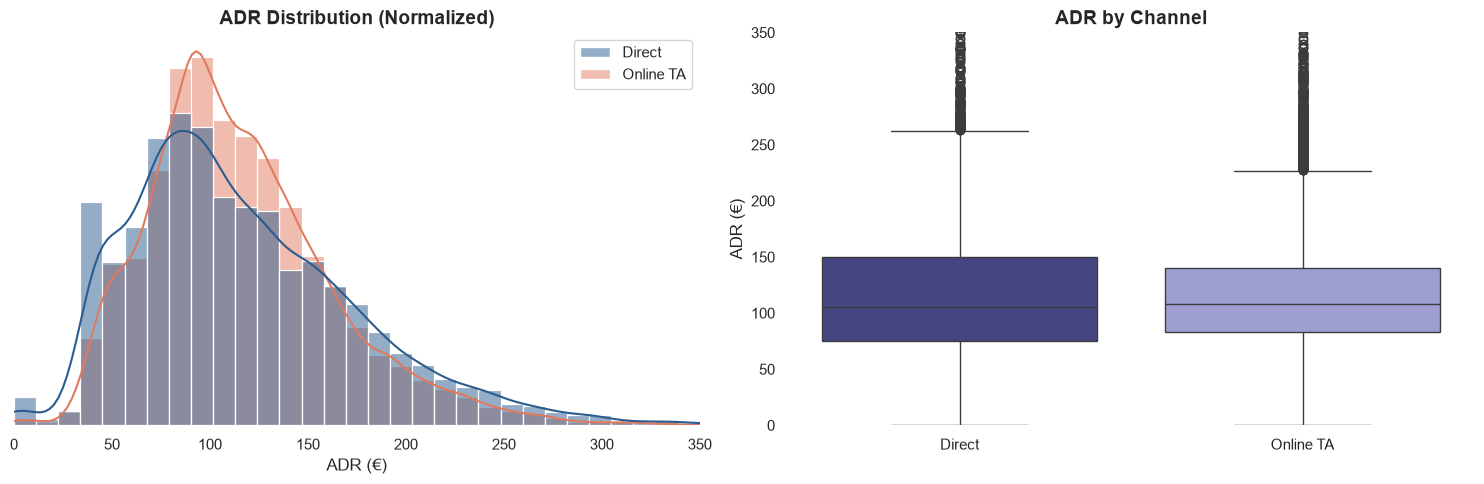

In [147]:
df_channels = df_confirmed[df_confirmed['market_segment'].isin(['Online TA', 'Direct'])]
ota_adr = df_channels.loc[df_channels['market_segment'] == 'Online TA', 'adr']
direct_adr = df_channels.loc[df_channels['market_segment'] == 'Direct', 'adr']

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(data=df_channels, x='adr', hue='market_segment', kde=True, bins=40, stat='density', common_norm=False, palette=['#2B5C8F', '#E07A5F'], ax=axes[0])
axes[0].set(title='ADR Distribution (Normalized)', xlabel='ADR (€)', ylabel='', xlim=(0, 350))
axes[0].set_yticks([])
axes[0].get_legend().set_title('')

sns.boxplot(data=df_channels, x='market_segment', y='adr', hue='market_segment', legend=False, palette=['#3B3B8C', '#9595D9'], ax=axes[1])
axes[1].set(title='ADR by Channel', xlabel='', ylabel='ADR (€)', ylim=(0, 350))

for ax in axes:
    ax.title.set_weight('bold')
    ax.title.set_size(14)
    ax.grid(False)

plt.tight_layout()
sns.despine(left=True, bottom=True)
plt.show()

In [148]:
# Test 1: all bookings together
t_stat, p_value = stats.ttest_ind(ota_adr, direct_adr, equal_var=False)
print('All bookings together')
print(f'Online TA: n = {len(ota_adr)}, mean ADR = €{ota_adr.mean():.2f}')
print(f'Direct:    n = {len(direct_adr)}, mean ADR = €{direct_adr.mean():.2f}')
print(f't = {t_stat:.2f}, p-value = {p_value:.4f}')

All bookings together
Online TA: n = 33055, mean ADR = €115.72
Direct:    n = 9919, mean ADR = €116.51
t = -1.23, p-value = 0.2192


The p-value is 0.2192, so for all bookings together I find **no clear difference**. But before I trust this, I want to check one thing. The two channels may have a different mix of hotels, and the Resort Hotel has lower prices on average than the City Hotel. Let me check the share of each hotel in each channel, and repeat the test **inside each hotel**.

In [149]:
# Share of each hotel inside each channel (%)
print(pd.crosstab(df_channels['market_segment'], df_channels['hotel'], normalize='index').mul(100).round(1))
print()

# Test 1 again, separately for each hotel
for hotel in ['City Hotel', 'Resort Hotel']:
    part = df_channels[df_channels['hotel'] == hotel]
    ota = part.loc[part['market_segment'] == 'Online TA', 'adr']
    direct = part.loc[part['market_segment'] == 'Direct', 'adr']
    t, p = stats.ttest_ind(ota, direct, equal_var=False)
    print(f'{hotel}: Online TA = €{ota.mean():.2f}, Direct = €{direct.mean():.2f}, p-value = {p:.2g}')

hotel           City Hotel  Resort Hotel
market_segment                          
Direct                46.1          53.9
Online TA             67.2          32.8

City Hotel: Online TA = €118.96, Direct = €122.20, p-value = 9.2e-06
Resort Hotel: Online TA = €109.07, Direct = €111.64, p-value = 0.019


**Result of Idea 1**

- For all bookings together, there is no clear difference (Online TA €115.72, Direct €116.51, p = 0.22).
- The check shows why: **Direct has more Resort bookings (54%) than Online TA (33%)**, and the Resort Hotel is cheaper on average. This hides a small difference.
- Inside each hotel, Direct guests pay **a little more**: €122.20 vs €118.96 in the City Hotel (p < 0.0001) and €111.64 vs €109.07 in the Resort Hotel (p = 0.019). The difference is only about **€2.6-3.2 per night (2-3%)**. It is statistically visible, but small in business terms.
- **Conclusion:** Online TA guests do **not** get lower prices than Direct guests. The hotel does not need to lower prices to win Direct bookings.
- Online TA commissions are not in this dataset. In the hotel industry they are often 15–20%, but this is an outside estimate, not a result of my analysis.

**Idea 2. Do guests with special requests cancel less?**

- Method: Chi-square test for two groups (with and without special requests) and two results (canceled or not).
- H₀: cancellation does not depend on special requests. H₁: it depends.

In [150]:
# Test 2: all bookings together
table = pd.crosstab(df['has_special_requests'], df['is_canceled'])
chi2, p_value, dof, expected = stats.chi2_contingency(table)

rates = df.groupby('has_special_requests')['canceled_pct'].mean().round(2)
print(rates)
print(f'chi-square = {chi2:.2f}, p-value = {p_value:.4e}')

has_special_requests
No requests      33.49
With requests    21.84
Name: canceled_pct, dtype: float64
chi-square = 1467.83, p-value = 0.0000e+00


In [151]:
# The same comparison inside each hotel
df.groupby(['hotel', 'has_special_requests'])['canceled_pct'].mean().round(2)

hotel         has_special_requests
City Hotel    No requests             38.55
              With requests           22.10
Resort Hotel  No requests             25.86
              With requests           21.42
Name: canceled_pct, dtype: float64

**Result of Idea 2**

- The cancellation rate is **33.5%** without requests and **21.8%** with at least one request (a difference of **11.7 percentage points**). The p-value is below 0.0001, so I reject H₀: the link is clear.
- With so many bookings, even a small difference can give a very small p-value. So I look at the size of the difference, too, and here it is big.
- The check by hotel shows that the effect is **mostly in the City Hotel**: 38.6% → 22.1% (-16.5 points). In the Resort Hotel it is smaller: 25.9% → 21.4% (-4.4 points).
- This shows a link, not a cause. Guests who plan to come may simply add more requests. The only way to know if asking for requests *reduces* cancellations is a real A/B test.

### <b> 6. Executive Summary and Recommendations </b>

**1. Give Direct bookings a reason to be chosen, with perks and not with discounts.**
- *Finding:* Online TA is 59% of bookings and cancels 35.6% of the time, while Direct cancels 14.9%. Direct guests pay the same price or a little more (+€2.6 to +€3.2 per night inside each hotel).
- *Action:* Offer perks (late check-out, a welcome drink, room preference) for booking on the hotel website. A price discount is not needed. Each Direct booking also saves the agency commission (often 15–20% in the industry; not in this data).

**2. Use stricter conditions for the riskiest bookings.**
- *Finding:* About one third of the booked revenue was in canceled bookings (about €11.5 million, estimated). Risk is the highest for Online TA and Groups bookings made far in advance (see the heatmap in 2.4). Cancellations also went up from 2015 to 2017, especially in the Resort Hotel (24% → 37% in July–August).
- *Action:* Test partial deposits, or a cheaper non-refundable rate, for bookings made more than 90 days before arrival from Online TA and Groups. Keep flexible rules for last-minute bookings. Review the contracts with tour operators and groups (release dates for unsold rooms).

**3. Ask guests for their preferences after booking, especially in the City Hotel.**
- *Finding:* Guests with at least one special request cancel less (21.8% vs 33.5%). The difference is biggest in the City Hotel (38.6% → 22.1%).
- *Action:* Add a short step in the booking process or a pre-arrival email (room floor, parking, crib, airport transfer). This is a link, not proof, so the hotel should test it and compare the results.

**4. Focus on families and plan the stay length.**
- *Finding:* Guests with children bring more revenue per booking (+43% City Hotel, +80% Resort Hotel). Guests who arrive on Friday stay the shortest (2.7 nights in the City Hotel).
- *Action:* Create family packages, especially for the Resort Hotel. Offer "stay one more night" deals for guests who arrive on Friday and other short-stay days.

**5. Grow loyalty among leisure guests.**
- *Finding:* Repeated guests cancel 2.5 to 5.5 times less than first-time guests, but they are only 3–5% of bookings, and mostly Corporate with lower prices.
- *Action:* Send a simple "thank you" email after the stay with an offer for the next booking, for Direct and Online TA guests. This can bring more repeated leisure guests at full price.

**6. Use the Resort Hotel's price pattern for planning.**
- *Finding:* The Resort Hotel's ADR is about 4 times higher in August than in January, while the number of guests changes much less.
- *Action:* Keep the high summer prices, and test special offers for the low months (January–February, November–December) to fill empty rooms.

### <b> Limitations </b>

- **Duplicates:** I removed about 32,000 exact duplicate rows. The data has no booking ID, so I could not be sure these are errors. If some were real bookings, the numbers would change a little.
- **Revenue is an estimate** (ADR × nights). The data does not show if the hotel kept any money from canceled bookings or sold the room again.
- **Currency** is not given in the dataset. I assume euros.
- **Short period and two hotels.** Data covers July 2015 – August 2017 for two hotels in Portugal. Seasonality is shown for 2016 only. The results may be different for other hotels or years.
- **Links, not causes.** The analysis shows how things are connected. It cannot prove that one thing causes another (for example, that special requests reduce cancellations). A real A/B test is needed for that.
- **Business explanations** (for example, why Online TA cancels more or why Non Refund cancels so much) are my ideas from hotel experience. The data does not confirm them.